### General imports

In [3]:
import pandas as pd
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import seaborn as sns
import random
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold






### Read data and Add necessary features

In [4]:
data_train = pd.read_csv('data/case1/train1.csv')
data_test = pd.read_csv('data/case1/test1.csv')

data_train['speed_krpm'] = data_train.speed_rpm / 1000
data_train['delta_p'] = data_train.outlet_pressure_bar - data_train.inlet_pressure_bar

data_test['speed_krpm'] = data_test.speed_rpm / 1000
data_test['delta_p'] = data_test.outlet_pressure_bar - data_test.inlet_pressure_bar


data_train.head()
print(len(data_train))
print(len(data_test))
print(data_train.columns)
print(data_train.describe())


X = data_train[['speed_krpm','power_w','delta_p']]
y = data_train['flow_m3_h']
y = np.asarray(y).reshape(-1, 1)




X_test = data_test[['speed_krpm','power_w','delta_p']]
y_test = data_test['flow_m3_h']
y_test = np.asarray(y_test).reshape(-1, 1)



480
120
Index(['pump_id', 'elapsed_s', 'operating_state', 'speed_rpm', 'power_w',
       'inlet_pressure_bar', 'outlet_pressure_bar', 'flow_m3_h', 'speed_krpm',
       'delta_p'],
      dtype='object')
        elapsed_s    speed_rpm      power_w  inlet_pressure_bar  \
count   480.00000   480.000000   480.000000          480.000000   
mean   3004.50000  3167.585295   703.518374            1.754341   
std    1733.83377   993.327115   553.346321            0.437575   
min      14.50000  1494.159036    63.185204            0.993489   
25%    1509.50000  2358.834776   227.256230            1.338162   
50%    3004.50000  3221.081886   551.359686            1.791819   
75%    4499.50000  4073.168668  1042.022701            2.112261   
max    5994.50000  4813.199117  2201.655665            2.514032   

       outlet_pressure_bar   flow_m3_h  speed_krpm     delta_p  
count           480.000000  480.000000  480.000000  480.000000  
mean              2.421464   18.792311    3.167585    0.667123  

### _Exploratory Data Analysis Done in playground_1_1, data already clean_

# Neural Network

## Manual Implementation

#### Helper functions

In [5]:
def ReLU(x):
     return np.maximum(0, x)


def ReLU_der(z):
     return (z > 0).astype(float)

def mse(y_true, y_pred):
     return np.mean((y_true - y_pred) ** 2)



### The main function, implemented with regularization by weight decay, alpha and lambda can be changed, same with epochs. Stops on a specific number of epochs

In [6]:
def ffnn(data_x, data_y, hidden_layers = [8], alpha_value = 0.01, 
         lambda_reg = 0.01, epochs = 1000, plot = False
):### base case 1 hidden layer with 8 neurons

    input_size = data_x.shape[1]
    layer_sizes = [input_size] + hidden_layers + [1]

    ### gotta make sure y has the right dimensions
    y = np.asarray(data_y).reshape(-1, 1)   

    weights = []
    biases = []
    alpha = alpha_value
    epoch = 0
    lambda_reg = lambda_reg

    ### I initialize the weights by the He initialization, and the biases as 0
    for i in range(len(layer_sizes) - 1):

        ## weights matrix is i(the current layer) x (i+1) (next layer)
        weights.append(
        np.random.randn(
            layer_sizes[i],
            layer_sizes[i + 1]
        ) * np.sqrt(2 / layer_sizes[i])
    )

        biases.append(
            np.zeros((1, layer_sizes[i + 1]))   
        )


    mse_values_and_penalty = [np.inf]

    while epoch < epochs:

        epoch += 1

        ##############################                ##############################
        ##############################  FORWARD PASS  ##############################
        ##############################                ##############################

        ## I take the first input layer also as activations which are later used 
        # for the first hidden layer of neurons

        activations = [data_x]
        zs = []

        for i in range(len(weights) - 1):
              # previous outputs x current layer weights + current layer biases
            z = activations[-1] @ weights[i] + biases[i]
            zs.append(z)

            a = ReLU(z)
            activations.append(a)


        #### Last step with linear activation:
        z_out = activations[-1] @ weights[-1] + biases[-1]
        a_out = z_out

        ## Penalty for huge weights
        l2_penalty = sum(np.sum(w ** 2) for w in weights)
        loss = mse(y, a_out) + (lambda_reg / 2) * l2_penalty

        mse_values_and_penalty.append(loss)


        ##############################                 ##############################
        ############################## BACKPROPAGATION ##############################
        ##############################                 ##############################

        n = data_x.shape[0]

        #### dL/da_out = dl/dz_out because linear activation function
        delta_out = (2 / n) * (a_out - y)

        ## Collect gradients dl/dz for other layers downstream contribution
        deltas = [delta_out]


        # Going backwards through layers to compute all dl/ da (dl / dz) * w for every layer
        for l in range(len(weights) - 2, -1, -1):
            delta = (deltas[0] @ weights[l + 1].T) * ReLU_der(zs[l])
            deltas.insert(0, delta)


        gradient_w = []
        gradient_b = []

        ### Compute the actual gradients by multiplying delta with the inputs at that step
        for l in range(len(weights)):

            gradient_w.append(
                activations[l].T @ deltas[l] + lambda_reg * weights[l]
            )

            gradient_b.append(
                np.sum(
                    deltas[l],
                    axis=0,
                    keepdims=True
                )
            )

        ### Finaly update weights and biases

        for l in range(len(weights)):

            weights[l] -= alpha * gradient_w[l]
            biases[l] -= alpha * gradient_b[l]



    if plot:
        plt.figure(figsize=(8, 5))
        plt.plot(mse_values_and_penalty[5::])
        plt.yscale("log")
        plt.xlabel("Epoch")
        plt.ylabel("MSE(log)")
        plt.title(f"Training Loss")
        plt.grid(True)
        plt.show()

        plt.figure(figsize=(10, 5))

        plt.boxplot(
                [w.flatten() for w in weights],
                tick_labels=[f"W{i+1}" for i in range(len(weights))]
            )

        plt.title("Weight Distribution per Layer")
        plt.ylabel("Weight Value")
        plt.grid(True)

        plt.show()

    return weights, biases, mse_values_and_penalty



def predict(X, weights, biases):

    a = X
    for i in range(len(weights) - 1):
        a = ReLU(a @ weights[i] + biases[i]) #### ReLU for all steps except the last one
    return a @ weights[-1] + biases[-1]


### Now let's apply the manual implementation for 3 initial features

#### Cross validation to choose alpha, lambda and architecture

In [7]:


alpha_values = [0.01, 0.003, 0.001]
lambda_reg_values = [0.001, 0.002, 0.003, 0.005, 0.01]
layers = [[5], [8], [8, 4], [16, 8], [32,16]]

kf = KFold(n_splits=5, shuffle=True, random_state=42)

results = []

X = np.asarray(X)
y = np.asarray(y).reshape(-1, 1)

for alpha in alpha_values:
    for lam in lambda_reg_values:
        for architecture in layers:

            fold_rmse = []
            fold_r2 = []

            for train_idx, val_idx in kf.split(X):

                X_train, X_val = X[train_idx], X[val_idx]
                y_train, y_val = y[train_idx], y[val_idx]

                # Standardize X 
                scaler_X = StandardScaler()
                X_train_st = scaler_X.fit_transform(X_train)
                X_val_st = scaler_X.transform(X_val)



                # Train FFNN
                weights, biases, losses = ffnn(
                    hidden_layers=architecture,
                    alpha_value=alpha,
                    lambda_reg=lam,
                    epochs=2000,
                    data_x=X_train_st,
                    data_y=y_train
                )

                # Predict
                y_pred = predict(X_val_st, weights, biases)

                # Evaluate
                rmse = np.sqrt(mse(y_val, y_pred))
                r2 = r2_score(y_val, y_pred)

                fold_rmse.append(rmse)
                fold_r2.append(r2)

            results.append({
                "alpha": alpha,
                "lambda_reg": lam,
                "layers": architecture,
                "mean_RMSE": np.mean(fold_rmse),
                "std_RMSE": np.std(fold_rmse),
                "mean_R2": np.mean(fold_r2),
                "std_R2": np.std(fold_r2)
            })

results_df = pd.DataFrame(results)

# Sort by lowest mean RMSE
results_df = results_df.sort_values("mean_RMSE")

print(results_df.head(10))

    alpha  lambda_reg    layers  mean_RMSE  std_RMSE   mean_R2    std_R2
28  0.003       0.001   [16, 8]   1.206361  0.145614  0.991080  0.002750
38  0.003       0.003   [16, 8]   1.206994  0.182803  0.990929  0.003673
49  0.003       0.010  [32, 16]   1.213239  0.131211  0.991009  0.002602
4   0.010       0.001  [32, 16]   1.214927  0.066762  0.991209  0.001133
39  0.003       0.003  [32, 16]   1.218894  0.048761  0.991126  0.001230
33  0.003       0.002   [16, 8]   1.219508  0.118871  0.990960  0.002577
43  0.003       0.005   [16, 8]   1.236244  0.123616  0.990751  0.002286
34  0.003       0.002  [32, 16]   1.246467  0.160683  0.990424  0.003294
29  0.003       0.001  [32, 16]   1.256099  0.194822  0.990291  0.003592
54  0.001       0.001  [32, 16]   1.256177  0.118939  0.990406  0.002724


#### Train and test with selected values

c:\Users\Dumitru\anaconda3\envs\ml\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


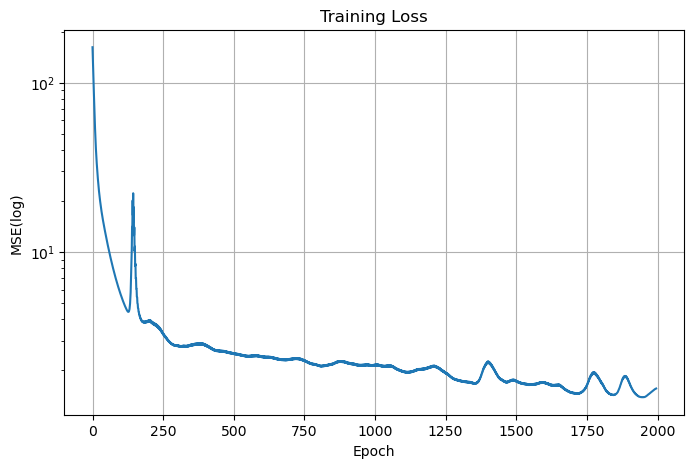

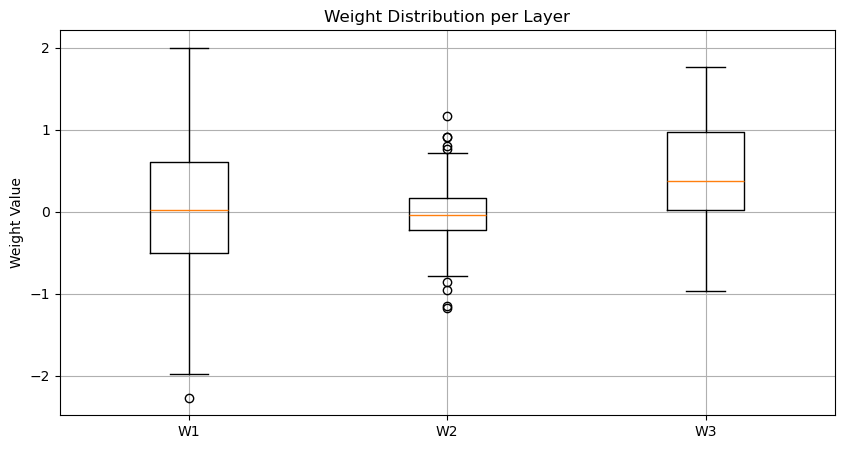

Train RMSE: 1.2001821219241522
Train R2: 0.9915458154145631
Test RMSE: 1.1375910550721928
Test R2: 0.9911208270489796


In [8]:
### train
scaler = StandardScaler()
X_st = scaler.fit_transform(X)
X_test_st = scaler.transform(X_test)

weights, biases, loss = ffnn(X_st, y, [32, 16], alpha_value=0.003, lambda_reg = 0.002,
                             epochs = 2000, plot = True)

y_pred = predict(X_st, weights, biases)
print(f"Train RMSE: {np.sqrt(mse(y, y_pred))}")
print(f"Train R2: {r2_score(y, y_pred)}")



y_test_pred = predict(X_test_st, weights, biases)
print(f"Test RMSE: {np.sqrt(mse(y_test, y_test_pred))}")
print(f"Test R2: {r2_score(y_test, y_test_pred)}")

## Library Implementation

In [9]:
import numpy as np
import pandas as pd

from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

In [10]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(
        activation="relu",
        solver="sgd",
        max_iter=2000,
        random_state=42,
        early_stopping=False,
        batch_size=X.shape[0]
    ))
])

param_grid = {"mlp__hidden_layer_sizes": [(5,),(8,),(8, 4),(16, 8),(32, 16)],
"mlp__learning_rate_init": [0.01, 0.003, 0.001],
"mlp__alpha": [0.001, 0.002, 0.003, 0.005, 0.01]}

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [11]:

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=kf,
    n_jobs=-1,
)

grid_search.fit(X, y)
print("Best parameters:", grid_search.best_params_)
print("Best CV RMSE:", -grid_search.best_score_)

c:\Users\Dumitru\anaconda3\envs\ml\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1771: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Best parameters: {'mlp__alpha': 0.003, 'mlp__hidden_layer_sizes': (32, 16), 'mlp__learning_rate_init': 0.003}
Best CV RMSE: 0.9111565883405508


In [12]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Test RMSE:", rmse)
print("Test R2:", r2)

Test RMSE: 0.7700869708370881
Test R2: 0.9959310745814629


c:\Users\Dumitru\anaconda3\envs\ml\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


### PLOT

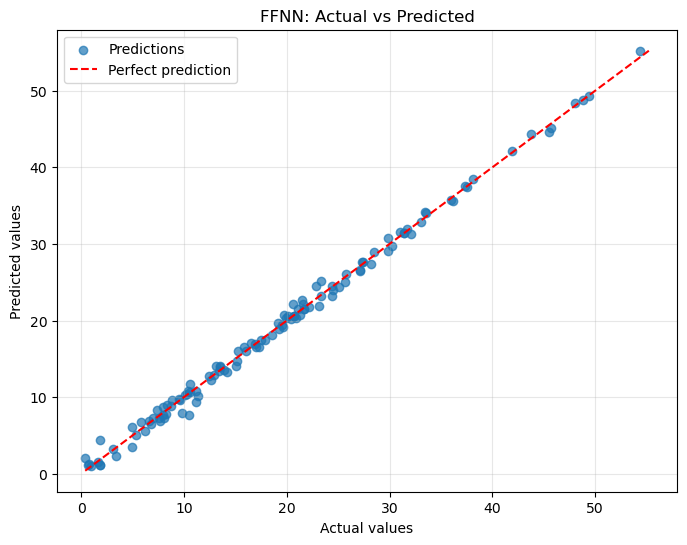

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7, label='Predictions')

# Perfect prediction line
min_val = min(np.min(y_test), np.min(y_pred))
max_val = max(np.max(y_test), np.max(y_pred))

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    label='Perfect prediction'
)

plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.title('FFNN: Actual vs Predicted')
plt.legend()
plt.grid(alpha=0.3)
plt.show()